In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

WORKDIR = 'C:/Users/cristiano.nascimento/git/LSTM_giroscopio_acelerometro'
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Code/DataPrep/"+data_hora

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_96652\847897453.py:15: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch
c:\Users\cristiano.nascimento\git\LSTM_giroscopio_acelerometro\.venv\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR+'/Code/DataPrep/activity_recognition_data_watch_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [4]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [5]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [6]:
""" import random
def split_and_shuffle_3d_arrays(array_data, labels_data):
    
    combined = list(zip(array_data, labels_data))
    
     # Set the seed for reproducibility
    #random.seed(42)
    
    # Shuffle the combined data in place
    #random.shuffle(combined)


    # Step 2: Separate into four parts based on label value
    # Filtering combined list by labels in each window
    grouped_data = {
        i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)
    }

    # Step 3: Interlace half of label=1 into half of label=0
    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    interlaced_0 = []

    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:
            interlaced_0.append(grouped_data[1][i])

    # Step 4: Interlace half of label=3 into half of label=2
    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    interlaced_2 = []

    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            interlaced_2.append(grouped_data[3][i])

    # Step 5: Interlace last half of label=0 into last half of label=3
    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    interlaced_3 = []

    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            interlaced_3.append(last_half_0[i])

    # Step 6: Concatenate the three resulting arrays vertically
    combined_result = interlaced_0 + interlaced_2 + interlaced_3

    # Step 7: Unzip the resulting array into separate data and labels
    data_result, labels_result = zip(*combined_result)

    # Converting back to numpy arrays for further processing if needed
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    return data_result,labels_result

 """

' import random\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    \n    combined = list(zip(array_data, labels_data))\n    \n     # Set the seed for reproducibility\n    #random.seed(42)\n    \n    # Shuffle the combined data in place\n    #random.shuffle(combined)\n\n\n    # Step 2: Separate into four parts based on label value\n    # Filtering combined list by labels in each window\n    grouped_data = {\n        i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)\n    }\n\n    # Step 3: Interlace half of label=1 into half of label=0\n    half_0 = len(grouped_data[0]) // 2\n    half_1 = len(grouped_data[1]) // 2\n    interlaced_0 = []\n\n    for i in range(half_0):\n        interlaced_0.append(grouped_data[0][i])\n        if i < half_1:\n            interlaced_0.append(grouped_data[1][i])\n\n    # Step 4: Interlace half of label=3 into half of label=2\n    half_2 = len(grouped_data[2]) // 2\n    half_3 = len(grouped_data[3]) // 2\n    int

In [7]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}

    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):
        modified_data, modified_labels = [], []
        used_ratios = set()

        for _ in range(3):  # Create 3 transition windows for each interlacing step
            while True:
                ratio = np.random.rand()
                if ratio not in used_ratios:
                    used_ratios.add(ratio)
                    break

            transition_data = np.zeros((200, 6))
            transition_labels = np.zeros((200, 1))
            split_index = int(200 * ratio)

            transition_data[:split_index] = prev_data_sample[:split_index]
            transition_labels[:split_index] = prev_label_sample[:split_index]
            transition_data[split_index:] = next_data_sample[split_index:]
            transition_labels[split_index:] = next_label_sample[split_index:]

            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

            mirrored_transition_data = np.flip(transition_data, axis=0)
            mirrored_transition_labels = np.flip(transition_labels, axis=0)
            modified_data.append(mirrored_transition_data)
            modified_labels.append(mirrored_transition_labels)

        return modified_data, modified_labels

    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1]
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1]
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1]
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])

    combined_result = interlaced_0 + interlaced_2 + interlaced_3
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n\n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):\n        modified_data, modified_labels = [], []\n        used_ratios = set()\n\n        for _ in range(3):  # Create 3 transition windows for each interlacing step\n            while True:\n                ratio = np.random.rand()\n                if ratio not in used_ratios:\n                    used_ratios.add(ratio)\n                    break\n\n            transition_data = np.zeros((200, 6))\n            transition_labels = np.zeros((200, 1))\n            split_index = int(200 * ratio)\n\n            transition_data[:split_index] = prev_data_sample[:split_index]\n            transition_labels[:split_index] = prev_label_sample[

In [8]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}

    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):
        modified_data = []  # Use lists to collect data
        modified_labels = []
        ratios = [0.10, 0.20, 0.40, 0.5, 0.60, 0.80, 0.90]  # Controlled split ratios for consistency

        for ratio in ratios:  # Create 3 transition windows with defined ratios
            transition_data = np.zeros((200, 7))
            transition_labels = np.zeros((200, 1))
            split_index = int(200 * ratio)

            # Fill transition windows
            transition_data[:split_index] = prev_data_sample[:split_index]
            transition_labels[:split_index] = prev_label_sample[:split_index]
            transition_data[split_index:] = next_data_sample[split_index:]
            transition_labels[split_index:] = next_label_sample[split_index:]
            transition_labels[:] = label_value  # Assign label to all entries
            
            # Append transition window to lists
            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

            # Mirrored transition window
            mirrored_transition_data = np.flip(transition_data, axis=0)
            mirrored_transition_labels = np.flip(transition_labels, axis=0)
            mirrored_transition_labels[:] = label_value
            modified_data.append(mirrored_transition_data)
            modified_labels.append(mirrored_transition_labels)

        # Stack to ensure 3D array format for each set of transitions
        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:            
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1],
                5
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])
            if i == 0:
                print("*****************************janela anterior*******************************************")
                print(grouped_data[0][i][0])
                print(grouped_data[0][i][0].shape)
                print("******************************janela posterior*********************************")
                print(grouped_data[1][i][0])
                print(grouped_data[1][i][0].shape)
                print("*******************************transitions*******************************")
                print(transitions_data)

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1],
                4
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1],
                6
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])

    combined_result = interlaced_0 + interlaced_2 + interlaced_3
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    print("######################################################333")
    print(data_result.shape)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n\n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):\n        modified_data = []  # Use lists to collect data\n        modified_labels = []\n        ratios = [0.10, 0.20, 0.40, 0.5, 0.60, 0.80, 0.90]  # Controlled split ratios for consistency\n\n        for ratio in ratios:  # Create 3 transition windows with defined ratios\n            transition_data = np.zeros((200, 7))\n            transition_labels = np.zeros((200, 1))\n            split_index = int(200 * ratio)\n\n            # Fill transition windows\n            transition_data[:split_index] = prev_data_sample[:split_index]\n            transition_labels[:split_index] = prev_label_sample[:split_index]\n           

In [9]:
""" ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences) """

' ocurrences = ocurrence_unique_values(targets_data)\nprint(ocurrences) '

In [10]:
#print(grouped_data[0][1][0])

In [11]:
import numpy as np

# Example array with binary class indications, replace this with your actual array
#array_data = np.random.randint(0, 2, (4027, 7)).astype(float)  # Example data; replace with your own

def count_active_classes(array_data):
    # Sum across each row to get the number of classes present in each row
    active_classes_per_row = np.sum(array_data, axis=1)
    
    # Count unique values in active_classes_per_row to get how many rows have each class count
    unique_counts, count_of_rows = np.unique(active_classes_per_row, return_counts=True)
    
    # Map each unique count of active classes to the number of rows with that count
    count_summary = dict(zip(unique_counts.astype(int), count_of_rows))
    
    return count_summary

# Get the count of active classes for each row
#active_classes_count = count_active_classes(array_data)

# Print the results
""" for active_class_count, row_count in active_classes_count.items():
    print(f"Number of rows with {active_class_count} active classes: {row_count}") """


' for active_class_count, row_count in active_classes_count.items():\n    print(f"Number of rows with {active_class_count} active classes: {row_count}") '

In [12]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}
    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
    print(grouped_data)
    

    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):
        modified_data = []  # Use lists to collect data
        modified_labels = []
        ratios = [0.50,0.50, 0.50, 0.50, 0.50, 0.50]  # Controlled split ratios for consistency

        for ratio in ratios:  # Create 3 transition windows with defined ratios
            transition_data = np.zeros((200, 7))
            transition_labels = np.zeros((200, 1))
            split_index = int(200 * ratio)

            # Fill transition windows
            transition_data[:split_index] = prev_data_sample[200-split_index:]
            transition_data[split_index:] = next_data_sample[:200-split_index]
            transition_labels[:split_index] = prev_label_sample[200-split_index:]
            transition_labels[split_index:] = next_label_sample[:200-split_index]
            transition_labels[:] = label_value  # Assign label to all entries
            
            # Append transition window to lists
            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

            # Mirrored transition window
            mirrored_transition_data = np.flip(transition_data, axis=0)
            mirrored_transition_labels = np.flip(transition_labels, axis=0)
            mirrored_transition_labels[:] = label_value
            modified_data.append(mirrored_transition_data)
            modified_labels.append(mirrored_transition_labels) 

        # Stack to ensure 3D array format for each set of transitions
        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:            
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1],
                5
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])
            if i == 0:
                print("*****************************group_data[0][i]r*******************************************")
                print(grouped_data[0][i])
                #print(grouped_data[0][i].shape)
                print("*****************************janela anterior*******************************************")
                print(grouped_data[0][i][0])
                print(grouped_data[0][i][0].shape)
                print("******************************janela posterior*********************************")
                print(grouped_data[1][i][0])
                print(grouped_data[1][i][0].shape)
                print("*******************************transitions*******************************")
                print(transitions_data[0])

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1],
                4
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1],
                6
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])

    combined_result = interlaced_0 + interlaced_2 + interlaced_3
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    print("######################################################333")
    print(data_result.shape)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")\n    print(grouped_data)\n    \n\n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):\n        modified_data = []  # Use lists to collect data\n        modified_labels = []\n        ratios = [0.50,0.50, 0.50, 0.50, 0.50, 0.50]  # Controlled split ratios for consistency\n\n        for ratio in ratios:  # Create 3 transition windows with defined ratios\n            transition_data = np.zeros((200, 7))\n            transition_labels = np.zeros((200, 1))\n            split_index = int(200 * ratio)\n\n            # Fill transition windows\n            transition_data[:split_index] = prev_data_sample[200-split_ind

In [13]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}
    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
    print(grouped_data)
    
    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):
        modified_data = []  # Use lists to collect data
        modified_labels = []
        ratios = [0.50, 0.50]  # Controlled split ratios for consistency

        for ratio in ratios:
            transition_data = np.zeros((200, 7))
            transition_labels = np.zeros((200, 1))

            # Define the weights for smooth transition
            weight_prev = np.linspace(1, 0, 40)[:, None]  # Decreasing weights for last 40 points
            weight_next = np.linspace(0, 1, 160)[:, None]  # Increasing weights for first 160 points

            # Apply weighted average for smooth transition
            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)
            transition_data[40:] = next_data_sample[:160] * weight_next + prev_data_sample[-160:] * (1 - weight_next)

            # Label transition as well
            transition_labels[:40] = prev_label_sample[160:] * weight_prev + next_label_sample[:40] * (1 - weight_prev)
            transition_labels[40:] = next_label_sample[:160] * weight_next + prev_label_sample[-160:] * (1 - weight_next)
            transition_labels[:] = label_value

            # Append transition window to lists
            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

        # Stack to ensure 3D array format for each set of transitions
        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    # Rest of the function remains unchanged
    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:            
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1],
                5
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1],
                4
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1],
                6
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])

    combined_result = interlaced_0 + interlaced_2 + interlaced_3
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    print("######################################################333")
    print(data_result.shape)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")\n    print(grouped_data)\n    \n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):\n        modified_data = []  # Use lists to collect data\n        modified_labels = []\n        ratios = [0.50, 0.50]  # Controlled split ratios for consistency\n\n        for ratio in ratios:\n            transition_data = np.zeros((200, 7))\n            transition_labels = np.zeros((200, 1))\n\n            # Define the weights for smooth transition\n            weight_prev = np.linspace(1, 0, 40)[:, None]  # Decreasing weights for last 40 points\n            weight_next = np.linspace(0, 1, 160)[:, None]  # Increasing weight

In [14]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}
    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
    print(grouped_data)
    
    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):
        modified_data = []
        modified_labels = []
        ratios = [0.50, 0.50]  # Controlled split ratios for consistency

        for ratio in ratios:
            transition_data = np.zeros((200, 7))
            transition_labels = np.zeros((200, 1))

            # Define the weights for smooth transition
            weight_prev = np.linspace(1, 0, 40)[:, None]
            weight_next = np.linspace(0, 1, 160)[:, None]

            # Apply weighted average for smooth transition
            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)
            transition_data[40:] = next_data_sample[:160] * weight_next + prev_data_sample[-160:] * (1 - weight_next)

            # Label transition as well
            transition_labels[:40] = prev_label_sample[160:] * weight_prev + next_label_sample[:40] * (1 - weight_prev)
            transition_labels[40:] = next_label_sample[:160] * weight_next + prev_label_sample[-160:] * (1 - weight_next)

            # Check for presence of labels 0, 1, 2, or 3 in the transition window
            unique_labels_in_window = np.unique(transition_labels)
            if any(label in unique_labels_in_window for label in [0, 1, 2, 3]):
                transition_labels[:] = label_value  # Apply label only if condition is met

            # Append transition window to lists
            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

        # Stack to ensure 3D array format for each set of transitions
        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    # Rest of the function remains unchanged
    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:            
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1],
                5
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1],
                4
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1],
                6
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])

    combined_result = interlaced_0 + interlaced_2 + interlaced_3
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    print("######################################################333")
    print(data_result.shape)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")\n    print(grouped_data)\n    \n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample, label_value):\n        modified_data = []\n        modified_labels = []\n        ratios = [0.50, 0.50]  # Controlled split ratios for consistency\n\n        for ratio in ratios:\n            transition_data = np.zeros((200, 7))\n            transition_labels = np.zeros((200, 1))\n\n            # Define the weights for smooth transition\n            weight_prev = np.linspace(1, 0, 40)[:, None]\n            weight_next = np.linspace(0, 1, 160)[:, None]\n\n            # Apply weighted average for smooth transition\n            transition_data

In [15]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}
    #print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
    #print(grouped_data)
    
    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):
        # Initialize lists to hold transition data and labels
        modified_data = []
        modified_labels = []

        # Define weights for the data transition
        weight_prev = np.linspace(1, 0, 40)[:, None]
        weight_next = np.linspace(0, 1, 160)[:, None]

        # Create transition data by blending prev and next samples
        transition_data = np.zeros((200, 7))
        transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)
        transition_data[40:] = next_data_sample[:160] * weight_next + prev_data_sample[-160:] * (1 - weight_next)

        # Determine the unique label in the relevant segments of prev and next samples
        unique_prev_labels = np.unique(prev_label_sample[160:])
        unique_next_labels = np.unique(next_label_sample[:160])

        # Apply label conditions based on unique values in prev and next segments
        if len(unique_prev_labels) == 1 and len(unique_next_labels) == 1:
            if unique_prev_labels[0] == 0 and unique_next_labels[0] == 1:
                transition_labels = np.full((200, 1), 5)  # All points labeled as 5
            elif unique_prev_labels[0] == 2 and unique_next_labels[0] == 3:
                transition_labels = np.full((200, 1), 4)  # All points labeled as 4
            elif unique_prev_labels[0] == 3 and unique_next_labels[0] == 0:
                transition_labels = np.full((200, 1), 6)  # All points labeled as 6
            else:
                # If no condition is met, retain original labels
                transition_labels = np.concatenate([prev_label_sample[160:], next_label_sample[:160]])
        else:
            # If the segments don’t meet the condition, retain original labels
            transition_labels = np.concatenate([prev_label_sample[160:], next_label_sample[:160]])

        # Append the transition to the modified data and labels
        modified_data.append(transition_data)
        modified_labels.append(transition_labels)

        # Stack results to ensure 3D array format for each set of transitions
        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    # Rest of the function remains unchanged
    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    print(f"len 0: {half_0}, len 1: {half_1}")
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:            
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1]
                
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    print(f"len 2: {half_2}, len 3: {half_3}")
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1]
                
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    print(f"len last half 3: {len(last_half_3)}, len last half 0: {len(last_half_0)}")
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1]
                
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])
    
    last_half_2 = grouped_data[2][half_2:]
    last_half_1 = grouped_data[1][half_1:]
            

    combined_result = interlaced_0 + interlaced_2 + interlaced_3 + last_half_2 + last_half_1
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    #print("######################################################333")
    #print(data_result.shape)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n    #print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")\n    #print(grouped_data)\n    \n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):\n        # Initialize lists to hold transition data and labels\n        modified_data = []\n        modified_labels = []\n\n        # Define weights for the data transition\n        weight_prev = np.linspace(1, 0, 40)[:, None]\n        weight_next = np.linspace(0, 1, 160)[:, None]\n\n        # Create transition data by blending prev and next samples\n        transition_data = np.zeros((200, 7))\n        transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)\n        transition_data[40:] =

In [16]:
""" ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences) """

' ocurrences = ocurrence_unique_values(targets_data)\nprint(ocurrences) '

In [17]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}
    #print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
    #print(grouped_data)
    
    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):
        # Initialize lists to hold transition data and labels
        modified_data = []
        modified_labels = []

        for pass_num in range(2):  # Run the transition twice
        # Generate weights slightly differently for each pass
            if pass_num == 0:
                weight_prev = np.linspace(1, 0, 40)[:, None]
                weight_next = np.linspace(0, 1, 160)[:, None]
            else:
                weight_prev = np.linspace(0.9, 0.1, 40)[:, None]  # Slightly adjusted for second pass
                weight_next = np.linspace(0.1, 0.9, 160)[:, None]

            # Create transition data by blending prev and next samples
            transition_data = np.zeros((200, 7))
            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)
            transition_data[40:] = next_data_sample[:160] * weight_next + prev_data_sample[-160:] * (1 - weight_next)

            # Optional: Add minimal noise for variation
            transition_data += np.random.normal(0, 0.01, transition_data.shape)

            # Determine the unique label in the relevant segments of prev and next samples
            unique_prev_labels = np.unique(prev_label_sample[160:])
            unique_next_labels = np.unique(next_label_sample[:160])

            # Apply label conditions based on unique values in prev and next segments
            if len(unique_prev_labels) == 1 and len(unique_next_labels) == 1:
                if unique_prev_labels[0] == 0 and unique_next_labels[0] == 1:
                    transition_labels = np.full((200, 1), 5)  # All points labeled as 5
                elif unique_prev_labels[0] == 2 and unique_next_labels[0] == 3:
                    transition_labels = np.full((200, 1), 4)  # All points labeled as 4
                elif unique_prev_labels[0] == 3 and unique_next_labels[0] == 0:
                    transition_labels = np.full((200, 1), 6)  # All points labeled as 6
                else:
                    # If no condition is met, retain original labels
                    transition_labels = np.concatenate([prev_label_sample[160:], next_label_sample[:160]])
            else:
                # If the segments don’t meet the condition, retain original labels
                transition_labels = np.concatenate([prev_label_sample[160:], next_label_sample[:160]])


            # Append the transition to the modified data and labels
            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

        # Stack results to ensure 3D array format for each set of transitions
        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    # Rest of the function remains unchanged
    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    half_0 = len(grouped_data[0]) // 2
    half_1 = len(grouped_data[1]) // 2
    print(f"len 0: {half_0}, len 1: {half_1}")
    for i in range(half_0):
        interlaced_0.append(grouped_data[0][i])
        if i < half_1:            
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1]
                
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])

    half_2 = len(grouped_data[2]) // 2
    half_3 = len(grouped_data[3]) // 2
    print(f"len 2: {half_2}, len 3: {half_3}")
    for i in range(half_2):
        interlaced_2.append(grouped_data[2][i])
        if i < half_3:
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1]
                
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    last_half_3 = grouped_data[3][half_3:]
    last_half_0 = grouped_data[0][half_0:]
    print(f"len last half 3: {len(last_half_3)}, len last half 0: {len(last_half_0)}")
    for i in range(len(last_half_3)):
        interlaced_3.append(last_half_3[i])
        if i < len(last_half_0):
            transitions_data, transitions_labels = create_transitions(
                last_half_3[i][0], last_half_0[i][0],
                last_half_3[i][1], last_half_0[i][1]
                
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(last_half_0[i])
    
    last_half_2 = grouped_data[2][half_2:]
    last_half_1 = grouped_data[1][half_1:]
            

    combined_result = interlaced_0 + interlaced_2 + interlaced_3 + last_half_2 + last_half_1
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)
    
    #print("######################################################333")
    #print(data_result.shape)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n    #print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")\n    #print(grouped_data)\n    \n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):\n        # Initialize lists to hold transition data and labels\n        modified_data = []\n        modified_labels = []\n\n        for pass_num in range(2):  # Run the transition twice\n        # Generate weights slightly differently for each pass\n            if pass_num == 0:\n                weight_prev = np.linspace(1, 0, 40)[:, None]\n                weight_next = np.linspace(0, 1, 160)[:, None]\n            else:\n                weight_prev = np.linspace(0.9, 0.1, 40)[:, None]  # Slightly adjusted for second pass\n              

In [18]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}

    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):
        modified_data, modified_labels = [], []

        for pass_num in range(2):
            if pass_num == 0:
                weight_prev = np.linspace(1, 0, 40)[:, None]
                weight_next = np.linspace(0, 1, 160)[:, None]
            else:
                weight_prev = np.linspace(0.9, 0.1, 40)[:, None]
                weight_next = np.linspace(0.1, 0.9, 160)[:, None]

            transition_data = np.zeros((200, 7))
            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)
            transition_data[40:] = next_data_sample[:160] * weight_next + prev_data_sample[-160:] * (1 - weight_next)

            transition_data += np.random.normal(0, 0.01, transition_data.shape)

            unique_prev_labels = np.unique(prev_label_sample[160:])
            unique_next_labels = np.unique(next_label_sample[:160])

            if len(unique_prev_labels) == 1 and len(unique_next_labels) == 1:
                if unique_prev_labels[0] == 0 and unique_next_labels[0] == 1:
                    transition_labels = np.full((200, 1), 5)
                elif unique_prev_labels[0] == 2 and unique_next_labels[0] == 3:
                    transition_labels = np.full((200, 1), 4)
                elif unique_prev_labels[0] == 3 and unique_next_labels[0] == 0:
                    transition_labels = np.full((200, 1), 6)
                else:
                    transition_labels = np.concatenate([prev_label_sample[160:], next_label_sample[:160]])
            else:
                transition_labels = np.concatenate([prev_label_sample[160:], next_label_sample[:160]])

            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    interlaced_0, interlaced_2, interlaced_3 = [], [], []

    interval_0_1 = max(1, len(grouped_data[0]) // (len(grouped_data[1]) + 1))
    interval_2_3 = max(1, len(grouped_data[2]) // (len(grouped_data[3]) + 1))
    interval_3_0 = max(1, len(grouped_data[3]) // (len(grouped_data[0]) + 1))

    for i, data_0 in enumerate(grouped_data[0]):
        interlaced_0.append(data_0)
        if (i + 1) % interval_0_1 == 0 and i < len(grouped_data[1]):
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1]
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])

    for i, data_2 in enumerate(grouped_data[2]):
        interlaced_2.append(data_2)
        if (i + 1) % interval_2_3 == 0 and i < len(grouped_data[3]):
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1]
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])

    for i, data_3 in enumerate(grouped_data[3]):
        interlaced_3.append(data_3)
        if (i + 1) % interval_3_0 == 0 and i < len(grouped_data[0]):
            transitions_data, transitions_labels = create_transitions(
                grouped_data[3][i][0], grouped_data[0][i][0],
                grouped_data[3][i][1], grouped_data[0][i][1]
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            interlaced_3.append(grouped_data[0][i])

    combined_result = interlaced_0 + interlaced_2 + interlaced_3
    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n\n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):\n        modified_data, modified_labels = [], []\n\n        for pass_num in range(2):\n            if pass_num == 0:\n                weight_prev = np.linspace(1, 0, 40)[:, None]\n                weight_next = np.linspace(0, 1, 160)[:, None]\n            else:\n                weight_prev = np.linspace(0.9, 0.1, 40)[:, None]\n                weight_next = np.linspace(0.1, 0.9, 160)[:, None]\n\n            transition_data = np.zeros((200, 7))\n            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)\n            transition_data[40:] = next_data_sample[:160] * weight_next + pr

In [19]:
""" ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences) """

' ocurrences = ocurrence_unique_values(targets_data)\nprint(ocurrences) '

In [20]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(array_data, labels_data):
    combined = list(zip(array_data, labels_data))
    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}

    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):
        modified_data, modified_labels = [], []

        for pass_num in range(1):
            if pass_num == 0:
                weight_prev = np.linspace(1, 0, 40)[:, None]
                weight_next = np.linspace(0, 1, 160)[:, None]
            else:
                weight_prev = np.linspace(0.9, 0.1, 40)[:, None]
                weight_next = np.linspace(0.1, 0.9, 160)[:, None]

            transition_data = np.zeros((200, 7))
            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)
            transition_data[40:] = next_data_sample[:160] * weight_next + prev_data_sample[-160:] * (1 - weight_next)
            transition_data += np.random.normal(0, 0.01, transition_data.shape)

            unique_prev_labels = np.unique(prev_label_sample[160:])
            unique_next_labels = np.unique(next_label_sample[:160])

            if len(unique_prev_labels) == 1 and len(unique_next_labels) == 1:
                if unique_prev_labels[0] == 0 and unique_next_labels[0] == 1:
                    transition_labels = np.full((200, 1), 5)
                elif unique_prev_labels[0] == 2 and unique_next_labels[0] == 3:
                    transition_labels = np.full((200, 1), 4)
                elif unique_prev_labels[0] == 3 and unique_next_labels[0] == 0:
                    transition_labels = np.full((200, 1), 6)
                else:
                    transition_labels = np.concatenate([prev_label_sample[:], next_label_sample[:]])
            else:
                transition_labels = np.concatenate([prev_label_sample[:], next_label_sample[:]])

            modified_data.append(transition_data)
            modified_labels.append(transition_labels)

        modified_data = np.stack(modified_data)
        modified_labels = np.stack(modified_labels)

        return modified_data, modified_labels

    interlaced_0, interlaced_2, interlaced_3 = [], [], []
    leftovers_1, leftovers_2 = set(range(len(grouped_data[1]))), set(range(len(grouped_data[2])))

    interval_0_1 = max(1, len(grouped_data[0]) // (len(grouped_data[1]) + 1))
    interval_2_3 = max(1, len(grouped_data[2]) // (len(grouped_data[3]) + 1))
    interval_3_0 = max(1, len(grouped_data[3]) // (len(grouped_data[0]) + 1))

    for i, data_0 in enumerate(grouped_data[0]):
        interlaced_0.append(data_0)
        if (i + 1) % interval_0_1 == 0 and i < len(grouped_data[1]):
            transitions_data, transitions_labels = create_transitions(
                grouped_data[0][i][0], grouped_data[1][i][0],
                grouped_data[0][i][1], grouped_data[1][i][1]
            )
            interlaced_0.extend(zip(transitions_data, transitions_labels))
            interlaced_0.append(grouped_data[1][i])
            leftovers_1.discard(i)

    for i, data_2 in enumerate(grouped_data[2]):
        interlaced_2.append(data_2)
        if (i + 1) % interval_2_3 == 0 and i < len(grouped_data[3]):
            transitions_data, transitions_labels = create_transitions(
                grouped_data[2][i][0], grouped_data[3][i][0],
                grouped_data[2][i][1], grouped_data[3][i][1]
            )
            interlaced_2.extend(zip(transitions_data, transitions_labels))
            interlaced_2.append(grouped_data[3][i])
            leftovers_2.discard(i)

    for i, data_3 in enumerate(grouped_data[3]):
        #interlaced_3.append(data_3)
        if (i + 1) % interval_3_0 == 0 and i < len(grouped_data[0]):
            transitions_data, transitions_labels = create_transitions(
                grouped_data[3][i][0], grouped_data[0][i][0],
                grouped_data[3][i][1], grouped_data[0][i][1]
            )
            interlaced_3.extend(zip(transitions_data, transitions_labels))
            #interlaced_3.append(grouped_data[0][i])

    leftovers_data_1 = [grouped_data[1][i] for i in leftovers_1]
    leftovers_data_2 = [grouped_data[2][i] for i in leftovers_2]
    combined_result = interlaced_0 + interlaced_2 + interlaced_3 + leftovers_data_1 + leftovers_data_2
    
    print("***************************************************************")
    print(leftovers_data_1)
    print(len(leftovers_data_1))
    print("&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&")
    print(leftovers_data_2)
    print(len(leftovers_data_2))

    data_result, labels_result = zip(*combined_result)
    data_result = np.array(data_result)
    labels_result = np.array(labels_result)

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(array_data, labels_data):\n    combined = list(zip(array_data, labels_data))\n    grouped_data = {i: [item for item in combined if np.unique(item[1][:, 0])[0] == i] for i in range(4)}\n\n    def create_transitions(prev_data_sample, next_data_sample, prev_label_sample, next_label_sample):\n        modified_data, modified_labels = [], []\n\n        for pass_num in range(1):\n            if pass_num == 0:\n                weight_prev = np.linspace(1, 0, 40)[:, None]\n                weight_next = np.linspace(0, 1, 160)[:, None]\n            else:\n                weight_prev = np.linspace(0.9, 0.1, 40)[:, None]\n                weight_next = np.linspace(0.1, 0.9, 160)[:, None]\n\n            transition_data = np.zeros((200, 7))\n            transition_data[:40] = prev_data_sample[160:] * weight_prev + next_data_sample[:40] * (1 - weight_prev)\n            transition_data[40:] = next_data_sample[:160] * weight_next + pr

In [21]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(variable_data, labels_data, subjects_range):
    # Initialize lists for transition windows
    transition_windows_1 = []
    transition_windows_2 = []
    transition_windows_3 = []

    # Function to create transition windows for given class pairs
    def create_transition_windows(data, labels, class_a, class_b, transition_label, exclude_indices):
        transition_windows = []

        # Select unique class windows
        windows_class_a = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_a and i not in exclude_indices]
        windows_class_b = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_b and i not in exclude_indices]

        # Randomly select one third of each window type
        selected_windows_class_a = random.sample(windows_class_a, len(windows_class_a) // 3)
        selected_windows_class_b = random.sample(windows_class_b, len(windows_class_b) // 3)
        
        # Track excluded indices to avoid reuse in other transitions
        exclude_indices.update([i for i, _ in selected_windows_class_a])
        exclude_indices.update([i for i, _ in selected_windows_class_b])

        # Create pairs and transition windows
        for (_, w_a), (_, w_b) in zip(selected_windows_class_a, selected_windows_class_b):
            # Create the transition window as the midpoint between two windows
            transition_window = (w_a + w_b) / 2
            transition_labels = np.full((200, 1), transition_label)
            
            # Concatenate class_a window, transition window, and class_b window
            combined_window = np.concatenate((w_a, transition_window, w_b), axis=0)
            combined_labels = np.concatenate((np.full((200, 1), class_a), transition_labels, np.full((200, 1), class_b)), axis=0)
            
            # Add to the respective list of transition windows
            transition_windows.append((combined_window, combined_labels))
        
        return transition_windows

    # Step 1 - Loop through each subject in the specified range
    for subject in subjects_range:
        subject_data = [d for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        subject_labels = [l for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        
        # Set to track indices of already used windows for different class combinations
        exclude_indices = set()

        # Labels 2 and 3 (Transition windows with label 4)
        transition_windows_1.extend(create_transition_windows(subject_data, subject_labels, 2, 3, 4, exclude_indices))
        
        # Labels 0 and 1 (Transition windows with label 5)
        transition_windows_2.extend(create_transition_windows(subject_data, subject_labels, 0, 1, 5, exclude_indices))
        
        # Labels 3 and 0 (Transition windows with label 6)
        transition_windows_3.extend(create_transition_windows(subject_data, subject_labels, 3, 0, 6, exclude_indices))

    # Step 2 - Combine all transition windows
    combined_result = transition_windows_1 + transition_windows_2 + transition_windows_3

    # Separate into data_result and labels_result
    data_result = np.array([window for window, _ in combined_result])
    labels_result = np.array([labels for _, labels in combined_result])

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(variable_data, labels_data, subjects_range):\n    # Initialize lists for transition windows\n    transition_windows_1 = []\n    transition_windows_2 = []\n    transition_windows_3 = []\n\n    # Function to create transition windows for given class pairs\n    def create_transition_windows(data, labels, class_a, class_b, transition_label, exclude_indices):\n        transition_windows = []\n\n        # Select unique class windows\n        windows_class_a = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_a and i not in exclude_indices]\n        windows_class_b = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_b and i not in exclude_indices]\n\n        # Randomly select one third of each window type\n        selected_windows_class_a = random.sample(windows_class_a, len(windows_class_a) // 3)\n        selected_windows_class_b = random.sample(windows_class_b, le

In [22]:
""" import numpy as np
import random

def split_and_shuffle_3d_arrays(variable_data, labels_data, subjects_range):
    # Initialize lists for transition windows
    transition_windows_1 = []
    transition_windows_2 = []
    transition_windows_3 = []

    # Function to create transition windows for given class pairs
    def create_transition_windows(data, labels, class_a, class_b, transition_label, exclude_indices):
        transition_windows = []

        # Select unique class windows
        windows_class_a = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_a and i not in exclude_indices]
        windows_class_b = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_b and i not in exclude_indices]

        # Randomly select one third of each window type
        selected_windows_class_a = random.sample(windows_class_a, len(windows_class_a) // 3)
        selected_windows_class_b = random.sample(windows_class_b, len(windows_class_b) // 3)
        
        # Track excluded indices to avoid reuse in other transitions
        exclude_indices.update([i for i, _ in selected_windows_class_a])
        exclude_indices.update([i for i, _ in selected_windows_class_b])

        # Create pairs and transition windows
        for (_, w_a), (_, w_b) in zip(selected_windows_class_a, selected_windows_class_b):
            # Create the transition window as the midpoint between two windows
            transition_window = (w_a + w_b) / 2
            transition_labels = np.full((200, 1), transition_label)
            
            # Concatenate class_a window, transition window, and class_b window
            # Stack w_a, transition_window, and w_b along a new axis to maintain shape (200, 7) for each
            combined_window = np.stack((w_a, transition_window, w_b), axis=0)  # Shape (3, 200, 7)
            combined_labels = np.stack((np.full((200, 1), class_a), transition_labels, np.full((200, 1), class_b)), axis=0)  # Shape (3, 200, 1)
            
            # Add to the respective list of transition windows
            transition_windows.append((combined_window, combined_labels))
        
        return transition_windows

    # Step 1 - Loop through each subject in the specified range
    for subject in subjects_range:
        subject_data = [d for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        subject_labels = [l for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        
        # Set to track indices of already used windows for different class combinations
        exclude_indices = set()

        # Labels 2 and 3 (Transition windows with label 4)
        transition_windows_1.extend(create_transition_windows(subject_data, subject_labels, 2, 3, 4, exclude_indices))
        
        # Labels 0 and 1 (Transition windows with label 5)
        transition_windows_2.extend(create_transition_windows(subject_data, subject_labels, 0, 1, 5, exclude_indices))
        
        # Labels 3 and 0 (Transition windows with label 6)
        transition_windows_3.extend(create_transition_windows(subject_data, subject_labels, 3, 0, 6, exclude_indices))

    # Step 2 - Combine all transition windows
    combined_result = transition_windows_1 + transition_windows_2 + transition_windows_3
    

    # Separate into data_result and labels_result
    data_result = np.array([window for window, _ in combined_result])
    labels_result = np.array([labels for _, labels in combined_result])

    return data_result, labels_result
 """

' import numpy as np\nimport random\n\ndef split_and_shuffle_3d_arrays(variable_data, labels_data, subjects_range):\n    # Initialize lists for transition windows\n    transition_windows_1 = []\n    transition_windows_2 = []\n    transition_windows_3 = []\n\n    # Function to create transition windows for given class pairs\n    def create_transition_windows(data, labels, class_a, class_b, transition_label, exclude_indices):\n        transition_windows = []\n\n        # Select unique class windows\n        windows_class_a = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_a and i not in exclude_indices]\n        windows_class_b = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_b and i not in exclude_indices]\n\n        # Randomly select one third of each window type\n        selected_windows_class_a = random.sample(windows_class_a, len(windows_class_a) // 3)\n        selected_windows_class_b = random.sample(windows_class_b, le

In [23]:
import numpy as np
import random

def split_and_shuffle_3d_arrays(variable_data, labels_data, subjects_range):
    # Initialize lists for transition windows
    transition_windows_1 = []
    transition_windows_2 = []
    transition_windows_3 = []

    # Function to create transition windows for given class pairs
    def create_transition_windows(data, labels, class_a, class_b, transition_label, exclude_indices):
        transition_windows = []

        # Select unique class windows
        windows_class_a = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_a and i not in exclude_indices]
        windows_class_b = [(i, w) for i, (w, l) in enumerate(zip(data, labels)) if np.unique(l) == class_b and i not in exclude_indices]
        
        print(f"imprimindo comprimento windows_class_a: {len(windows_class_a)}")
        print(f"imprimindo comprimento windows_class_b: {len(windows_class_b)}")

        # Randomly select one third of each window type
        selected_windows_class_a = random.sample(windows_class_a, len(windows_class_a) // 3)
        selected_windows_class_b = random.sample(windows_class_b, len(windows_class_b) // 3)
        
        # Track excluded indices to avoid reuse in other transitions
        exclude_indices.update([i for i, _ in selected_windows_class_a])
        exclude_indices.update([i for i, _ in selected_windows_class_b])

        # Create pairs and transition windows
        for (_, w_a), (_, w_b) in zip(selected_windows_class_a, selected_windows_class_b):
            # Sophisticated transition window using linear interpolation
            transition_window = np.zeros_like(w_a)
            for t in range(200):
                alpha = t / 199  # Smoothly varies from 0 to 1
                transition_window[t] = (1 - alpha) * w_a[t] + alpha * w_b[t]
            
            transition_labels = np.full((200, 1), transition_label)
            
            # Concatenate class_a window, transition window, and class_b window
            # Stack w_a, transition_window, and w_b along a new axis to maintain shape (200, 7) for each
            combined_window = np.stack((w_a, transition_window, w_b), axis=0)  # Shape (3, 200, 7)
            combined_labels = np.stack((np.full((200, 1), class_a), transition_labels, np.full((200, 1), class_b)), axis=0)  # Shape (3, 200, 1)
            
            # Add to the respective list of transition windows
            transition_windows.append((combined_window, combined_labels))
        
        return transition_windows

    # Step 1 - Loop through each subject in the specified range
    for subject in subjects_range:
        subject_data = [d for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        print(f"imprimindo comprimento de subject_data: {len(subject_data)}")
        
        
        subject_labels = [l for d, l in zip(variable_data, labels_data) if d[0, 0] == subject]
        print(f"imprimindo comprimento subject labels: {len(subject_labels)}")
        
        # Set to track indices of already used windows for different class combinations
        exclude_indices = set()

        # Labels 2 and 3 (Transition windows with label 4)
        transition_windows_1.extend(create_transition_windows(subject_data, subject_labels, 2, 3, 4, exclude_indices))
        
        # Labels 0 and 1 (Transition windows with label 5)
        transition_windows_2.extend(create_transition_windows(subject_data, subject_labels, 0, 1, 5, exclude_indices))
        
        # Labels 3 and 0 (Transition windows with label 6)
        transition_windows_3.extend(create_transition_windows(subject_data, subject_labels, 3, 0, 6, exclude_indices))

    # Step 2 - Combine all transition windows
    combined_result = transition_windows_1 + transition_windows_2 + transition_windows_3
    
    # Separate into data_result and labels_result
    data_result = np.array([window for window, _ in combined_result])
    labels_result = np.array([labels for _, labels in combined_result])

    return data_result, labels_result


In [24]:
#print (shuffled_labels)

In [25]:
#remove the null class
data=data.dropna()

# **Data Exploration**

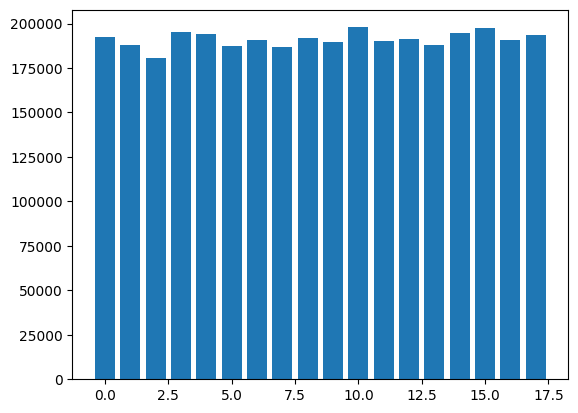

In [26]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

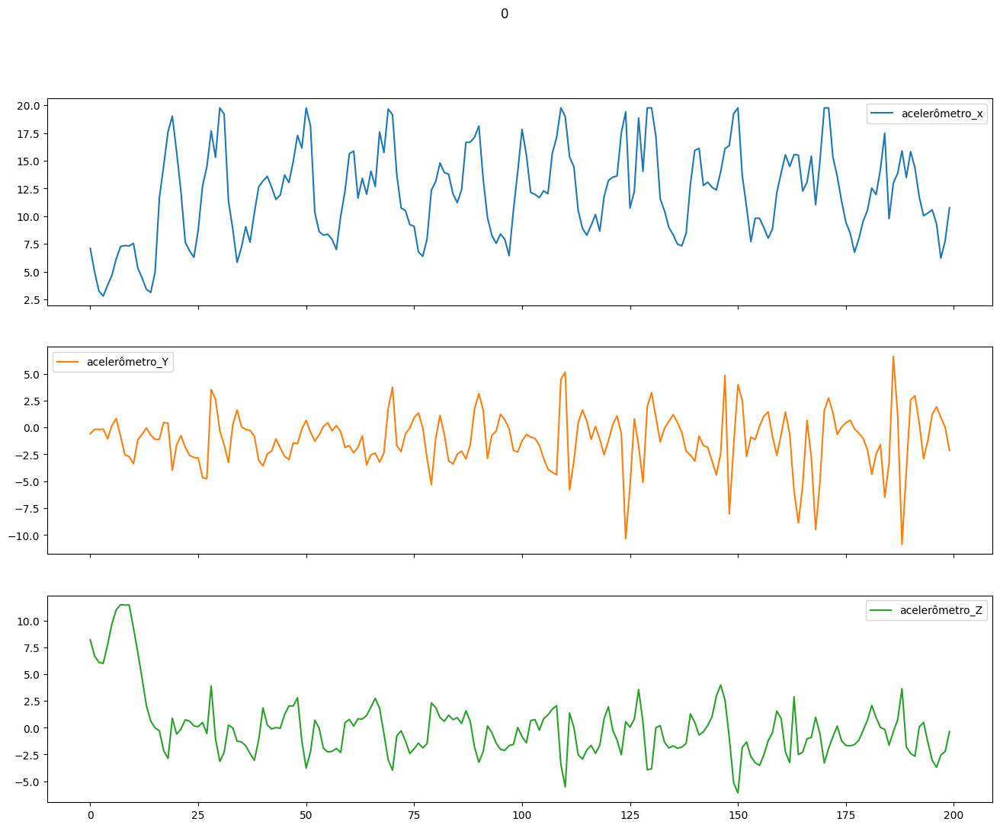

In [27]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

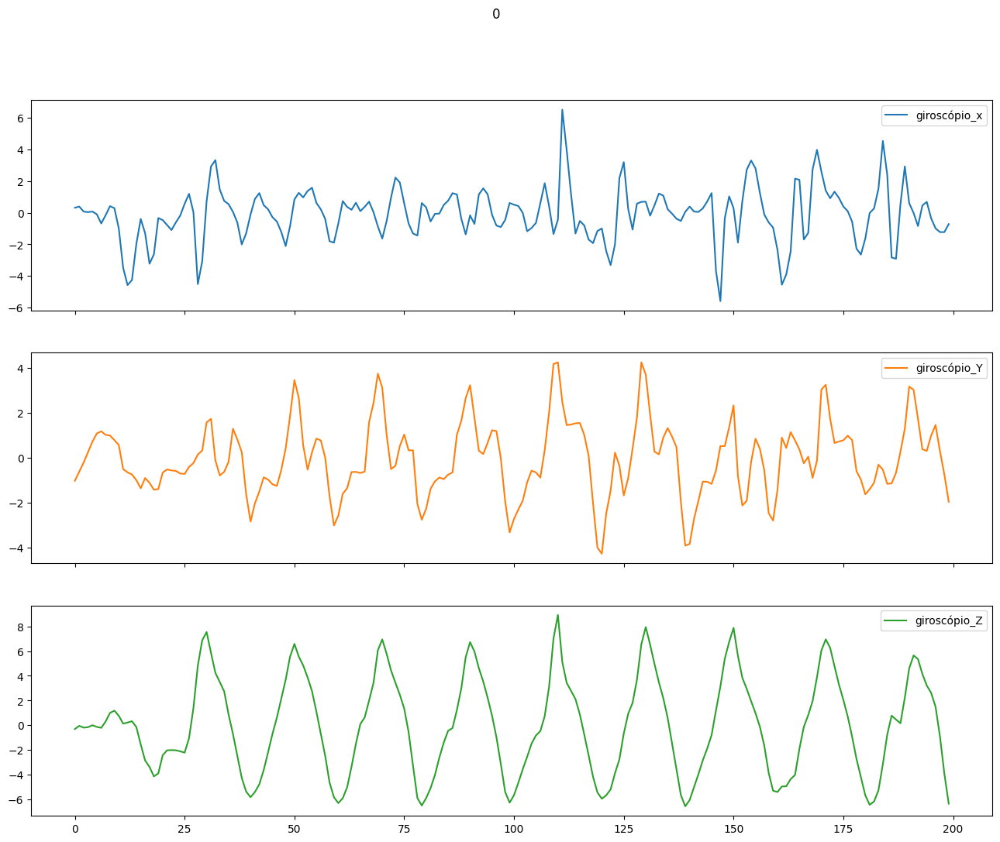

In [28]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:200].plot(title='0',subplots=True, figsize=(16, 12))

In [29]:
data = data[data.pessoa_x!=1629]

In [30]:
data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1610,
       1611, 1612, 1613, 1614, 1615, 1616, 1617, 1618, 1619, 1620, 1621,
       1622, 1623, 1624, 1625, 1626, 1627, 1628, 1630, 1631, 1632, 1633,
       1634, 1635, 1636, 1637, 1638, 1639, 1640, 1641, 1642, 1643, 1644,
       1645, 1646, 1647, 1648, 1649, 1650], dtype=int64)

In [31]:
data = data.reset_index(drop=True)

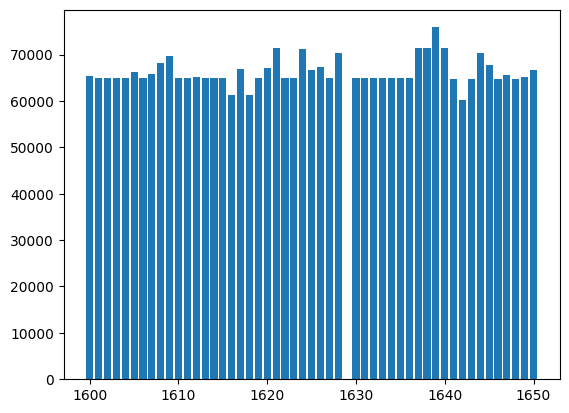

In [32]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [33]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,2,3,4])]

In [34]:
# Define the mapping dictionary
mapping_dict = {2:1,3:2,4:3}

In [35]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [36]:
data.shape

(733273, 10)

In [37]:
data['atividade'].value_counts()

atividade
2    187842
3    186897
0    185324
1    173210
Name: count, dtype: int64

In [38]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [39]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [40]:
data.shape

(733273, 10)

In [41]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [42]:
print(grouped_data)

atividade       0       1       2       3
pessoa_x                                 
1600       3603.0  3604.0  3604.0  3604.0
1601       3601.0  3601.0  3601.0  3602.0
1602       3603.0  3603.0  3603.0  3699.0
1603       3603.0  3602.0  3603.0  3601.0
1604       3603.0  3604.0  3603.0  3603.0
1605       3603.0  3602.0  3602.0  3602.0
1606       3603.0  3603.0  3603.0  3603.0
1607       3603.0  3602.0  3601.0  3602.0
1608       3603.0  3603.0  3603.0  3603.0
1609       3603.0  3603.0  3603.0  3603.0
1610       3603.0  3603.0  3603.0  3603.0
1611       3603.0  3603.0  3603.0  3603.0
1612       3603.0  3603.0  3603.0  3603.0
1613       3600.0  3602.0  3602.0  3601.0
1614       3601.0  3616.0  3601.0  3601.0
1615       3603.0  3603.0  3603.0  3603.0
1616       3603.0  3603.0  3603.0  3603.0
1617       3603.0  3603.0  3603.0  3603.0
1618       3602.0  3603.0  3603.0  3603.0
1619       3600.0  3600.0  3600.0  3600.0
1620       3603.0  3603.0  3603.0  3603.0
1621       3600.0  3600.0  7918.0 

In [43]:
nan_values = grouped_data[grouped_data.isnull().any(axis=1)].index

In [44]:
nan_values_array = nan_values.to_numpy()

In [45]:
print(nan_values)

Index([1637, 1640, 1642], dtype='int64', name='pessoa_x')


In [46]:
data = data[~data['pessoa_x'].isin([1637,1640,1642])]

In [47]:
data['atividade'].value_counts()

atividade
3    178834
2    175317
1    173210
0    172798
Name: count, dtype: int64

In [48]:
def prune_subjects_with_too_many_records(df):

    import pandas as pd

    # Assuming df is your DataFrame
    # Filtering for specific 'pessoa_x' values: 1621, 1628, and 1650
    filtered_df = df[(df['pessoa_x'].isin([1621, 1628, 1645,1650]))]

    # Keeping other 'pessoa_x' values between 1600 and 1650
    other_df = df[(df['pessoa_x'] >= 1600) & (df['pessoa_x'] <= 1650) & (~df['pessoa_x'].isin([1621, 1628, 1645,1650]))]

    # Group by 'pessoa_x' and 'atividade', and get first 3603 rows for each group
    filtered_limited_df = filtered_df.groupby(['pessoa_x', 'atividade']).head(3603)

    # Concatenate the filtered and the other dataframes
    result_df = pd.concat([filtered_limited_df, other_df])

    # Reset index if needed
    result_df = result_df.reset_index(drop=True)

    # Display the resulting DataFrame
    return result_df



In [49]:
data = prune_subjects_with_too_many_records(data)

In [50]:
data['atividade'].value_counts()

atividade
3    171127
1    171050
0    171036
2    171002
Name: count, dtype: int64

In [51]:
grouped_data2 = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()

In [52]:
print(grouped_data2)

atividade     0     1     2     3
pessoa_x                         
1600       3603  3604  3604  3604
1601       3601  3601  3601  3602
1602       3603  3603  3603  3699
1603       3603  3602  3603  3601
1604       3603  3604  3603  3603
1605       3603  3602  3602  3602
1606       3603  3603  3603  3603
1607       3603  3602  3601  3602
1608       3603  3603  3603  3603
1609       3603  3603  3603  3603
1610       3603  3603  3603  3603
1611       3603  3603  3603  3603
1612       3603  3603  3603  3603
1613       3600  3602  3602  3601
1614       3601  3616  3601  3601
1615       3603  3603  3603  3603
1616       3603  3603  3603  3603
1617       3603  3603  3603  3603
1618       3602  3603  3603  3603
1619       3600  3600  3600  3600
1620       3603  3603  3603  3603
1621       3600  3600  3603  3603
1622       3603  3604  3603  3603
1623       3603  3603  3588  3603
1624       3604  3603  3604  3604
1625       3603  3616  3604  3603
1626       3603  3604  3604  3603
1627       360

In [53]:
def mark_mixed_windows(labels_data):
    mixed_count = 0
    count_2_3 = 0
    count_0_1 = 0
    count_3_0 = 0
    count_0_2 = 0
    count_0_3 = 0
    count_1_2 = 0
    count_1_3 = 0
    count_1_0 = 0
    count_2_0 = 0
    count_2_1 = 0
    count_3_1 = 0
    count_3_2 = 0
    
    # Loop over each window by index to modify the array directly
    for i in range(labels_data.shape[0]):
        window = labels_data[i]
        
        # Check if the first and last labels in the window match specific transitions
        first_label = window[0]  # First label in the window (since it's 1D now)
        last_label = window[-1]  # Last label in the window (1D array)
        
        # Check for transitions between specific label pairs
        if first_label == 2 and last_label == 3:
            labels_data[i] = 4  # Transition from 2 to 3
            count_2_3 += 1
        elif first_label == 0 and last_label == 1:
            labels_data[i] = 5  # Transition from 0 to 1
            count_0_1 += 1
        elif first_label == 3 and last_label == 0:
            labels_data[i] = 6  # Transition from 1 to 2
            count_3_0 += 1
        elif first_label == 0 and last_label == 2:
            labels_data[i] = 7  # Transition from 2 to 1
            count_0_2 += 1
        elif first_label == 0 and last_label == 3:
            labels_data[i] = 8
            count_0_3 += 1
        elif first_label == 1 and last_label == 2:
            labels_data[i] = 9
            count_1_2 += 1
        elif first_label == 1 and last_label == 3:
            labels_data[i] = 10  # Transition from 0 to 1
            count_1_3 += 1
        elif first_label == 1 and last_label == 0:
            labels_data[i] = 11  # Transition from 1 to 2
            count_1_0 += 1
        elif first_label == 2 and last_label == 0:
            labels_data[i] = 12  # Transition from 2 to 1
            count_2_0 += 1
        elif first_label == 2 and last_label == 1:
            labels_data[i] = 13
            count_2_1 += 1
        elif first_label == 3 and last_label == 1:
            labels_data[i] = 14
            count_3_1 += 1
        elif first_label == 3 and last_label == 2:
            labels_data[i] = 15
            count_3_2 += 1
            
    print(f"count_2_3 :{count_2_3}, count_0_1: {count_0_1}, count_3_0: {count_3_0}, count_0_2: {count_0_2} ")
    print(f"count_0_3 :{count_0_3}, count_1_2: {count_1_2}, count_1_3: {count_1_3}, count_1_0: {count_1_0} ")
    print(f"count_2_0 :{count_2_0}, count_2_1: {count_2_1}, count_3_1: {count_3_1}, count_3_2: {count_3_2} ")
          
    
    return mixed_count, labels_data

# This update fixes the issue by treating the `labels_data` as a 1D array for each window. The code should now work with your (453, 200) 2D array.


In [54]:
import numpy as np

# Example array of shape (4027, 7) with categorical data in the second dimension
#array_data = np.random.randint(0, 7, (4027, 7))  # Replace with your actual data

def count_classes(array_data):
    # Flatten the array to count across all elements in the second dimension
    flattened_data = array_data.flatten()
    
    # Count unique values and their occurrences
    unique_classes, counts = np.unique(flattened_data, return_counts=True)
    
    # Create a dictionary to map classes to their counts
    class_counts = dict(zip(unique_classes, counts))
    
    return class_counts

# Get the counts for each class
#class_counts = count_classes(array_data)

# Print the counts



# **Models**

In [55]:
import numpy as np

# Example labels data array of shape (3152, 200, 1)
#labels_data = np.random.randint(0, 3, (3152, 200, 1))  # Replace with your actual labels array

def count_mixed_windows(labels_data):
    mixed_count = 0
    
    # Loop over each window
    for window in labels_data:
        # Flatten the window to a 1D array and find unique label values
        unique_labels = np.unique(window)
        
        # Check if there is more than one unique label in the window
        if len(unique_labels) > 1:
            mixed_count += 1
    
    return mixed_count

# Count the mixed windows
#mixed_window_count = count_mixed_windows(labels_data)
#print(f"Number of mixed windows: {mixed_window_count}")


In [56]:
def delete_segments_not_fully_filled(df_data_windowed,df_label_windowed):
    indexes = np.where(df_label_windowed == -1)[0]
    unique_arr = np.unique(indexes, return_index=True)[0]
    new_df_label_windowed = np.delete(df_label_windowed,unique_arr,axis=0)
    new_df_data_windowed = np.delete(df_data_windowed,unique_arr,axis=0)
    return (new_df_data_windowed,new_df_label_windowed)

In [57]:
import numpy as np

def ocurrence_unique_values(targets_test):

    # Example of 3D array with the format (256, 200, 1)
    #data = np.random.randint(0, 3, (256, 200, 1))

    # Reshape to (256, 200) to simplify the processing
    data_reshaped = targets_test.reshape(targets_test.shape[0], 200)

    # Get unique values per window (each window has 200 rows)
    # Since the second dimension always contains the same value, we can just select the first column for each window
    unique_values = data_reshaped[:, 0]

    # Count occurrences of each unique value (0, 1, 2)
    unique, counts = np.unique(unique_values, return_counts=True)

    # Create a dictionary to show the counts of 0, 1, and 2
    occurrences = dict(zip(unique, counts))
    return occurrences


In [58]:
import numpy as np

def count_unique_value_windows(data):
    # Reshape to (n, 200) by flattening the third dimension (since it's (426, 200, 1))
    data_reshaped = data.reshape(data.shape[0], 200)
    
    # Initialize a dictionary to count occurrences of windows with unique values
    occurrences = {0.: 0, 1.: 0, 2.: 0, 3.: 0, 4.: 0, 5.: 0, 6.: 0, 7.: 0, 8.: 0, 9.: 0, 
                   10.: 0, 11.: 0, 12.: 0, 13.: 0, 14.: 0, 15.: 0}

    # Iterate through each window
    for window in data_reshaped:
        # Check if the window contains only one unique value
        unique_vals = np.unique(window)
        if len(unique_vals) == 1:  # If only one unique value in the window
            occurrences[unique_vals[0]] += 1  # Increment the count for that value
    
    return occurrences

# Now the function works with the input of shape (426, 200, 1). 



In [59]:
def apply_segmentation_no_sliding_window(df_data):
# Define window size and step size
    window_size = 200
    step_size = 20

    # Calculate number of windows
    n_windows = int((df_data.shape[0] / window_size))

    # Create segmented data using sliding window
    segments = np.zeros((n_windows, window_size, df_data.shape[1]-3),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * window_size
        end_idx = start_idx + window_size
        #populate the 3d array only if the 200 segment has the value in label
        label_consistency = (df_data[['atividade']][start_idx:end_idx].nunique()==1) 
        if label_consistency[0] == True:
            segments[i] = df_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [60]:
def apply_segmentation_with_sliding_window(df_data):
    #creating sliding window for train data
    import numpy as np

    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-3),dtype=np.float32)
    targets = np.full((n_windows, window_size, 1),-1)
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        label_consistency = df_data[['atividade']][start_idx:end_idx].nunique()==1
        if label_consistency[0] == True:
            segments[i] = df_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
            targets[i] = df_data[['atividade']][start_idx:end_idx]
    return (segments,targets)

In [61]:
import numpy as np
from scipy.stats import mode  # Use mode to find the most common label

def apply_segmentation_with_sliding_window_transitions(df_data):
    window_size = 200
    step_size = 20

    n_windows = int((df_data.shape[0] - window_size) // step_size + 1)

    segments = np.zeros((n_windows, window_size, df_data.shape[1]-1), dtype=np.float32)
    targets = np.full((n_windows, window_size, 1), -1, dtype=np.int32)
    
    for i in range(n_windows):
        start_idx = i * step_size
        end_idx = start_idx + window_size
        
        # Fill segments with sensor data
        segments[i] = df_data[['pessoa_x', 'acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']][start_idx:end_idx]
        
        # Calculate the majority label for the window
        window_labels = df_data['atividade'][start_idx:end_idx]
        majority_label = mode(window_labels)[0][0]  # Gets the most frequent label

        # Assign the majority label to the entire window
        targets[i].fill(majority_label)

    return segments, targets


In [62]:
import numpy as np
def remove_useless_labels(labels_test,segments_test):

# Assuming array_3d is of shape (1239, 200, 6) and labels_1d is of shape (1239,)
    # Replace these with your actual arrays
    #array_3d = np.random.rand(1239, 200, 6)
    #labels_1d = np.random.randint(0, 9, size=(1239,))

    # Find the indices where labels are not 7 or 8
    valid_indices = np.where((labels_test != 7) & (labels_test != 8) & (labels_test != 9) 
                             & (labels_test != 10) & (labels_test != 11)
                             & (labels_test != 12) & (labels_test != 13)
                             & (labels_test != 14) & (labels_test != 15) )[0]

    # Filter both arrays
    filtered_labels_1d = labels_test[valid_indices]  # 1D array, indexed with 1 dimension
    filtered_array_3d = segments_test[valid_indices, :, :]  # 3D array, indexed with 3 dimensions

    return filtered_labels_1d, filtered_array_3d

    # Output the new shapes for verification
    #print("Filtered labels shape:", filtered_labels_1d.shape)
    #print("Filtered 3D array shape:", filtered_array_3d.shape)


In [63]:
print(data.pessoa_x.unique())

[1621 1628 1645 1650 1600 1601 1602 1603 1604 1605 1606 1607 1608 1609
 1610 1611 1612 1613 1614 1615 1616 1617 1618 1619 1620 1622 1623 1624
 1625 1626 1627 1630 1631 1632 1633 1634 1635 1636 1638 1639 1641 1643
 1644 1646 1647 1648 1649]


In [64]:
segments_data,targets_data = apply_segmentation_no_sliding_window(data)
print(segments_data.shape)
print(targets_data.shape)

(3421, 200, 7)
(3421, 200, 1)


In [65]:
segments_data,targets_data = delete_segments_not_fully_filled(segments_data,targets_data)
print(segments_data.shape)
print(targets_data.shape)

(3237, 200, 7)
(3237, 200, 1)


In [66]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

Label counts: {0: 161800, 1: 162000, 2: 161600, 3: 162000}


In [67]:
import numpy as np

def reorganize_labels(labels_test):

    # Example of a 1D array with length 1239 and values from 0 to 6
    #array_1d = np.random.randint(0, 7, size=1239)

    # Replace values 0 to 2 with 0
    labels_test = np.where(labels_test <= 3, 0, labels_test)

    # Replace values 3 to 6 with 1, 2, 3, and 4 respectively
    mapping = {4: 1, 5: 2, 6: 3}
    labels_test = np.vectorize(mapping.get)(labels_test, labels_test)  # Only changes values 3 to 6

    return labels_test


In [68]:
print(segments_data.shape)

(3237, 200, 7)


In [69]:
segments_data, targets_data = split_and_shuffle_3d_arrays(segments_data, targets_data,range(1600, 1651) )

imprimindo comprimento de subject_data: 68
imprimindo comprimento subject labels: 68
imprimindo comprimento windows_class_a: 17
imprimindo comprimento windows_class_b: 17
imprimindo comprimento windows_class_a: 17
imprimindo comprimento windows_class_b: 17
imprimindo comprimento windows_class_a: 12
imprimindo comprimento windows_class_b: 12
imprimindo comprimento de subject_data: 68
imprimindo comprimento subject labels: 68
imprimindo comprimento windows_class_a: 17
imprimindo comprimento windows_class_b: 17
imprimindo comprimento windows_class_a: 17
imprimindo comprimento windows_class_b: 17
imprimindo comprimento windows_class_a: 12
imprimindo comprimento windows_class_b: 12
imprimindo comprimento de subject_data: 68
imprimindo comprimento subject labels: 68
imprimindo comprimento windows_class_a: 17
imprimindo comprimento windows_class_b: 17
imprimindo comprimento windows_class_a: 17
imprimindo comprimento windows_class_b: 17
imprimindo comprimento windows_class_a: 12
imprimindo com

In [70]:
print(targets_data.shape)

(668, 3, 200, 1)


In [71]:
print(segments_data.shape)

(668, 3, 200, 7)


In [72]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

Label counts: {0: 85800, 1: 48000, 2: 47800, 3: 85600, 4: 47800, 5: 48000, 6: 37800}


In [73]:
print(targets_data.shape)

(668, 3, 200, 1)


In [74]:
# Flatten the second dimension (3) into the first dimension
targets_data = targets_data.reshape(-1, 200, 1)

In [75]:
print(targets_data.shape)

(2004, 200, 1)


In [76]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

Label counts: {0: 85800, 1: 48000, 2: 47800, 3: 85600, 4: 47800, 5: 48000, 6: 37800}


In [77]:
print(segments_data.shape)

(668, 3, 200, 7)


In [78]:
# Flatten the second dimension (3) into the first dimension
segments_data = segments_data.reshape(-1, 200, 7)

In [79]:
print(segments_data.shape)

(2004, 200, 7)


In [80]:
import numpy as np

def category_count_categorical(labels_test_categorical):

    # Assuming your data is stored in a variable called `data`
    # Replace this with the actual data if it's available

    # Sum along the rows to get the count for each category
    category_counts_categorical = np.sum(labels_test_categorical, axis=0)

    # Print the counts
    print("Category counts:", category_counts_categorical)


In [81]:
ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences)

{0: 429, 1: 240, 2: 239, 3: 428, 4: 239, 5: 240, 6: 189}


In [82]:
#segments_test, targets_test = add_transition_windows(segments_test, targets_test)

In [83]:
print(targets_data.shape)

(2004, 200, 1)


In [84]:
print(segments_data.shape)

(2004, 200, 7)


In [85]:
import numpy as np

# Assuming variable_data and label_data are your arrays
# variable_data has shape (2004, 200, 7) and label_data has shape (2004, 200, 1)

# Flatten the label array along the first dimension to make window indexing easier
labels_flattened = targets_data[:, 0, 0]  # Only take one value per window for class comparison

# Identify indices where the class label is 0 or 3
indices_class_0 = np.where(labels_flattened == 0)[0]
indices_class_3 = np.where(labels_flattened == 3)[0]

# Get the last 190 indices for class 0 and class 3
indices_to_remove = np.concatenate([indices_class_0[-190:], indices_class_3[-190:]])

# Remove the identified windows from both variable_data and label_data
segments_data = np.delete(segments_data, indices_to_remove, axis=0)
targets_data = np.delete(targets_data, indices_to_remove, axis=0)

# Output the shapes to verify the result
print("Original shape of variable_data:", targets_data.shape)
print("Original shape of label_data:", targets_data.shape)



Original shape of variable_data: (1624, 200, 1)
Original shape of label_data: (1624, 200, 1)


In [86]:
ocurrences = ocurrence_unique_values(targets_data)
print(ocurrences)

{0: 239, 1: 240, 2: 239, 3: 238, 4: 239, 5: 240, 6: 189}


In [87]:
print(targets_data)

[[[2]
  [2]
  [2]
  ...
  [2]
  [2]
  [2]]

 [[4]
  [4]
  [4]
  ...
  [4]
  [4]
  [4]]

 [[3]
  [3]
  [3]
  ...
  [3]
  [3]
  [3]]

 ...

 [[6]
  [6]
  [6]
  ...
  [6]
  [6]
  [6]]

 [[6]
  [6]
  [6]
  ...
  [6]
  [6]
  [6]]

 [[6]
  [6]
  [6]
  ...
  [6]
  [6]
  [6]]]


In [88]:
#mixed_window_count_data, targets_data = mark_mixed_windows(targets_data)

In [89]:
print(targets_data.shape)

(1624, 200, 1)


In [90]:
print(segments_data.shape)

(1624, 200, 7)


In [91]:
count_unique_values = count_unique_value_windows(targets_data)

In [92]:
print(count_unique_values)

{0.0: 239, 1.0: 240, 2.0: 239, 3.0: 238, 4.0: 239, 5.0: 240, 6.0: 189, 7.0: 0, 8.0: 0, 9.0: 0, 10.0: 0, 11.0: 0, 12.0: 0, 13.0: 0, 14.0: 0, 15.0: 0}


In [93]:
# Reshape the arrays to 2D, where each row corresponds to one time step across the entire dataset
segments_data = segments_data.reshape(-1, 7)  # Reshape to (324800, 7)
targets_data = targets_data.reshape(-1, 1)  # Reshape to (324800, 1)

# Concatenate horizontally
combined_data = np.hstack((segments_data, targets_data))

# Create a DataFrame
df_with_transitions = pd.DataFrame(combined_data, columns=['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade'])

# Check the shape to ensure it matches the expected length
print(df_with_transitions.shape)  # Should be (324800, 8)

# Display the first few rows
df_with_transitions.head()


(324800, 8)


,pessoa_x,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,atividade
0,1600.0,3.474884510,-3.864840031,8.326584816,-0.010927483,0.002573413,0.001553954,2.0
1,1600.0,3.427000523,-3.831321239,8.240393639,-0.009862218,-0.004883438,0.001553954,2.0
2,1600.0,3.474884510,-3.900753021,8.295459747,0.003986219,0.002573413,-0.003772368,2.0
3,1600.0,3.460519314,-3.845686436,8.237998962,0.001855691,-0.003818174,0.000488690,2.0
4,1600.0,3.448548317,-3.886387825,8.283489227,0.014638864,-0.002752910,-0.002707103,2.0


In [94]:
df_with_transitions.tail()

,pessoa_x,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,giroscópio_x,giroscópio_Y,giroscópio_Z,atividade
324795,1650.0,4.031677246,2.583609819,2.428135633,-1.996004820,1.817056656,0.687867165,6.0
324796,1650.0,4.097277641,2.231207371,2.524899244,-2.354768276,1.747732043,0.611647189,6.0
324797,1650.0,4.554120064,1.993919015,2.619774103,-2.726320744,1.726071358,0.405127764,6.0
324798,1650.0,5.024569035,1.862781286,2.563488960,-3.208408356,1.744290829,0.085979320,6.0
324799,1650.0,5.541230202,2.001851797,1.978807688,-3.836046934,1.803129911,-0.319450170,6.0


In [95]:
df_with_transitions.atividade.value_counts()

atividade
5.0    48000
1.0    48000
2.0    47800
4.0    47800
0.0    47800
3.0    47600
6.0    37800
Name: count, dtype: int64

In [96]:
segments_data,targets_data = apply_segmentation_with_sliding_window_transitions(df_with_transitions)
print(segments_data.shape)
print(targets_data.shape)

C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_96652\3444754129.py:22: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  majority_label = mode(window_labels)[0][0]  # Gets the most frequent label
C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_96652\3444754129.py:22: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer b

(16231, 200, 7)
(16231, 200, 1)


C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_96652\3444754129.py:22: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  majority_label = mode(window_labels)[0][0]  # Gets the most frequent label
C:\Users\cristiano.nascimento\AppData\Local\Temp\ipykernel_96652\3444754129.py:22: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer b

In [97]:
# Assuming your array is named 'data'
# Example: data = np.random.randint(0, 5, (3237, 200, 1))

# Reshape the array to 2D (ignoring the sequence dimension of 200)
flattened_labels = targets_data.reshape(-1)

# Use numpy's unique function to count occurrences of each label
unique_labels, counts = np.unique(flattened_labels, return_counts=True)

# Combine into a dictionary for better readability
label_counts = dict(zip(unique_labels, counts))

print("Label counts:", label_counts)

Label counts: {0: 525800, 1: 480400, 2: 524800, 3: 476000, 4: 430200, 5: 432000, 6: 377000}


In [98]:
print(count_unique_values)

{0.0: 239, 1.0: 240, 2.0: 239, 3.0: 238, 4.0: 239, 5.0: 240, 6.0: 189, 7.0: 0, 8.0: 0, 9.0: 0, 10.0: 0, 11.0: 0, 12.0: 0, 13.0: 0, 14.0: 0, 15.0: 0}


In [99]:
segments_data,targets_data = delete_segments_not_fully_filled(segments_data,targets_data)
print(segments_data.shape)
print(targets_data.shape)

(16231, 200, 7)
(16231, 200, 1)


In [100]:
count_unique_values = count_unique_value_windows(targets_data)

In [101]:
print(count_unique_values)

{0.0: 2629, 1.0: 2402, 2.0: 2624, 3.0: 2380, 4.0: 2151, 5.0: 2160, 6.0: 1885, 7.0: 0, 8.0: 0, 9.0: 0, 10.0: 0, 11.0: 0, 12.0: 0, 13.0: 0, 14.0: 0, 15.0: 0}


In [102]:
count_unique_values = count_unique_value_windows(targets_data)

In [103]:
print(count_unique_values)

{0.0: 2629, 1.0: 2402, 2.0: 2624, 3.0: 2380, 4.0: 2151, 5.0: 2160, 6.0: 1885, 7.0: 0, 8.0: 0, 9.0: 0, 10.0: 0, 11.0: 0, 12.0: 0, 13.0: 0, 14.0: 0, 15.0: 0}


In [104]:
segments_data,targets_data = delete_segments_not_fully_filled(segments_data,targets_data)
print(segments_data.shape)
print(targets_data.shape)

(16231, 200, 7)
(16231, 200, 1)


In [105]:
count_unique_values = count_unique_value_windows(targets_data)

In [106]:
print(count_unique_values)

{0.0: 2629, 1.0: 2402, 2.0: 2624, 3.0: 2380, 4.0: 2151, 5.0: 2160, 6.0: 1885, 7.0: 0, 8.0: 0, 9.0: 0, 10.0: 0, 11.0: 0, 12.0: 0, 13.0: 0, 14.0: 0, 15.0: 0}


In [107]:
""" # Print the number of mixed windows
print(f"Number of mixed windows: {mixed_window_count_data}")

# Example check of updated labels_data
print(targets_data) """

' # Print the number of mixed windows\nprint(f"Number of mixed windows: {mixed_window_count_data}")\n\n# Example check of updated labels_data\nprint(targets_data) '

In [108]:
# Count transition windows
transition_window_count_data = count_mixed_windows(targets_data)
print(f"Number of windows with transitions between labels: {transition_window_count_data}")

Number of windows with transitions between labels: 0


In [109]:
targets_test = targets_data.reshape(targets_data.shape[0],200)

In [110]:
print(targets_data.shape)

(16231, 200, 1)


In [111]:
print(targets_data)

[[[2]
  [2]
  [2]
  ...
  [2]
  [2]
  [2]]

 [[2]
  [2]
  [2]
  ...
  [2]
  [2]
  [2]]

 [[2]
  [2]
  [2]
  ...
  [2]
  [2]
  [2]]

 ...

 [[6]
  [6]
  [6]
  ...
  [6]
  [6]
  [6]]

 [[6]
  [6]
  [6]
  ...
  [6]
  [6]
  [6]]

 [[6]
  [6]
  [6]
  ...
  [6]
  [6]
  [6]]]


In [112]:
labels_data = targets_data[:,0]

In [113]:
print(labels_data)

[[2]
 [2]
 [2]
 ...
 [6]
 [6]
 [6]]


In [114]:
print(labels_data.shape)

(16231, 1)


In [115]:
print(segments_data.shape)

(16231, 200, 7)


In [116]:
#labels_data, segments_data = remove_useless_labels(labels_data,segments_data)

In [117]:
print(segments_data.shape)

(16231, 200, 7)


In [118]:
print(labels_data.shape)

(16231, 1)


In [119]:
print(segments_data.shape)

(16231, 200, 7)


In [120]:
labels_data = reorganize_labels(labels_data)

In [121]:
print(labels_data.shape)

(16231, 1)


In [122]:
print(labels_data)

[[0]
 [0]
 [0]
 ...
 [3]
 [3]
 [3]]


In [123]:
labels_data_categorical = to_categorical(labels_data,num_classes=4)

In [124]:
print(labels_data_categorical)

[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 ...
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [125]:
print(labels_data_categorical.shape)

(16231, 4)


In [126]:
category_count_categorical(labels_data_categorical)

Category counts: [10035.  2151.  2160.  1885.]


In [127]:
import numpy as np

# Function to count occurrences of each category
def count_categories(data):
    counts = {
        '[1, 0, 0, 0]': np.sum((data == [1., 0., 0., 0.]).all(axis=1)),
        '[0, 1, 0, 0]': np.sum((data == [0., 1., 0., 0.]).all(axis=1)),
        '[0, 0, 1, 0]': np.sum((data == [0., 0., 1., 0.]).all(axis=1)),
        '[0, 0, 0, 1]': np.sum((data == [0., 0., 0., 1.]).all(axis=1)),
    }
    return counts

# Count categories before removal
print("Category counts before removal:", count_categories(labels_data_categorical))

# Define the desired class count for the first category
desired_class_count = 2151

# Identify indices of the first class (1, 0, 0, 0) in labels_data_categorical
first_class_indices = np.where((labels_data_categorical == [1., 0., 0., 0.]).all(axis=1))[0]

# Randomly select indices to remove to balance the first class
indices_to_remove = np.random.choice(first_class_indices, size=(len(first_class_indices) - desired_class_count), replace=False)

# Remove the selected indices from both labels_data_categorical and segments_data
labels_data_categorical = np.delete(labels_data_categorical, indices_to_remove, axis=0)
segments_data = np.delete(segments_data, indices_to_remove, axis=0)

# Count categories after removal
print("Category counts after removal:", count_categories(labels_data_categorical))

# Print the shape of the new arrays to verify
print("New shape of labels_data_categorical:", labels_data_categorical.shape)
print("New shape of segments_data:", segments_data.shape)


Category counts before removal: {'[1, 0, 0, 0]': 10035, '[0, 1, 0, 0]': 2151, '[0, 0, 1, 0]': 2160, '[0, 0, 0, 1]': 1885}
Category counts after removal: {'[1, 0, 0, 0]': 2151, '[0, 1, 0, 0]': 2151, '[0, 0, 1, 0]': 2160, '[0, 0, 0, 1]': 1885}
New shape of labels_data_categorical: (8347, 4)
New shape of segments_data: (8347, 200, 7)


In [128]:
print(segments_data.shape)

(8347, 200, 7)


In [129]:
print(segments_data)

[[[ 1.6000000e+03  3.4940381e+00 -3.8552632e+00 ...  2.4208667e-02
    3.6482643e-03 -2.7081685e-03]
  [ 1.6000000e+03  3.4677019e+00 -3.8696284e+00 ...  2.1012874e-02
   -3.8085866e-03 -1.6556606e-02]
  [ 1.6000000e+03  3.4485483e+00 -3.8097734e+00 ... -7.7492660e-03
    2.5829999e-03  1.1140269e-02]
  ...
  [ 1.6000000e+03  3.9923515e+00 -3.5404844e+00 ... -1.1930387e-03
   -8.7213970e-04  1.3537260e-03]
  [ 1.6000000e+03  4.0333004e+00 -3.5546014e+00 ...  5.7994802e-03
   -4.2583756e-03 -2.4892099e-03]
  [ 1.6000000e+03  4.0837059e+00 -3.5563624e+00 ...  1.4882836e-02
    4.5587411e-03 -4.9401023e-03]]

 [[ 1.6000000e+03  3.4293947e+00 -3.7930140e+00 ... -5.6256615e-03
   -1.0196445e-02 -4.8392299e-03]
  [ 1.6000000e+03  3.4868555e+00 -3.8241386e+00 ...  5.0269826e-03
    8.9783147e-03 -1.6434367e-03]
  [ 1.6000000e+03  3.4868555e+00 -3.8696284e+00 ...  1.0353305e-02
    2.5867284e-03 -5.7817227e-04]
  ...
  [ 1.6000000e+03  5.8781013e+00 -2.5320742e+00 ... -4.2857421e-03
    2.8649

In [130]:
print(labels_data_categorical.shape)

(8347, 4)


In [131]:
segments_data[:, :, 0] = segments_data[:, :, 0].astype(int)

In [132]:
print(segments_data[:, :, 0])

[[1600. 1600. 1600. ... 1600. 1600. 1600.]
 [1600. 1600. 1600. ... 1600. 1600. 1600.]
 [1600. 1600. 1600. ... 1600. 1600. 1600.]
 ...
 [1650. 1650. 1650. ... 1650. 1650. 1650.]
 [1650. 1650. 1650. ... 1650. 1650. 1650.]
 [1650. 1650. 1650. ... 1650. 1650. 1650.]]


In [133]:
def split(segments_data, labels_data_categorical,interval):    
    import numpy as np

    # Assuming segments_data and labels_data_categorical are already defined as numpy arrays

    # Step 1: Convert the first position of all rows of the last dimension to INT format
    segments_data[:, :, 0] = segments_data[:, :, 0].astype(int)

    # Step 2: Zip segments_data and labels_data_categorical to maintain the rows of both arrays in the same index position
    zipped_data = list(zip(segments_data, labels_data_categorical))

    # Step 3: Remove all lines from zipped list where the segments of 200 points (window) have only the unique values {1600, 1601, 1602, 1603, 1604} in the first column
    filtered_data = [
        (segment, label) for segment, label in zipped_data
        if set(segment[:, 0]).issubset(interval)
    ]

    # Step 4: Unzip the new list into two final arrays: segments_test and targets_test
    if filtered_data:  # Check to avoid errors if the list is empty
        segments_test, targets_test = zip(*filtered_data)

        # Convert the results back to numpy arrays
        segments_test = np.array(segments_test)
        targets_test = np.array(targets_test)
        # Step 5: Remove the first position of the last dimension in segments_test to get shape (n, 200, 6)
        segments_test = segments_test[:, :, 1:]
    else:
        segments_test = np.array([])
        targets_test = np.array([])
        
    return segments_test,targets_test


    # segments_test and targets_test are now ready to use


In [134]:
segments_test,targets_test = split(segments_data,labels_data_categorical,{1600, 1601, 1602, 1603, 1604})

In [135]:
print(segments_test.shape)

(706, 200, 6)


In [136]:
print(segments_test)

[[[ 9.6460886e+00 -7.7242935e-01  8.1298113e-01  1.9149460e-02
   -3.3526535e-03  6.0267333e-04]
  [ 9.5575037e+00 -7.0060325e-01  7.6270288e-01  4.1520014e-02
   -1.9331619e-02  6.9942600e-03]
  [ 9.5814457e+00 -6.8144965e-01  7.6749128e-01  2.5541047e-02
   -1.2221247e-03  6.0267333e-04]
  ...
  [ 9.7849531e+00 -6.6469026e-01  7.2439563e-01  1.0221239e-01
    3.8208105e-02 -1.8574217e-02]
  [ 9.5383501e+00 -6.2159461e-01  7.5312608e-01  1.6506299e-01
    8.4014475e-02 -6.1184794e-02]
  [ 9.5790510e+00 -5.0188452e-01  6.5975219e-01  1.3630085e-01
    2.9685991e-02 -4.5205828e-02]]

 [[ 9.6221466e+00 -6.3117141e-01  7.7467388e-01 -3.7300766e-02
   -4.4227117e-03  2.7337349e-03]
  [ 9.6341181e+00 -6.4074820e-01  8.5128832e-01 -4.9018674e-02
   -1.6165388e-04 -7.9189092e-03]
  [ 9.5694742e+00 -6.7666125e-01  7.6030868e-01 -5.8611114e-02
    9.4286557e-03 -2.5931199e-03]
  ...
  [ 2.9385834e+00 -2.0021513e+00  9.1406136e+00  1.4952318e-02
    7.6224995e-03 -1.3848438e-04]
  [ 2.9098530e+0

In [137]:
print(targets_test.shape)

(706, 4)


In [138]:
segments_val,targets_val = split(segments_data,labels_data_categorical,{1605, 1606, 1607, 1608, 1609, 1610, 1611, 1612,1613})

In [139]:
print(segments_val.shape)

(1411, 200, 6)


In [140]:
segments_train,targets_train = split(segments_data,labels_data_categorical,{1614,1615,1616,1617,1618,1619,1620,1621,1622,1623,1624,
                                                                            1625,1626,1627,1628,1629,1630,1631,1632,1633,1634,1635,1636,1637,1638,
                                                                            1639,1640,1641,1642,1643,1644,1645,1646,1647,1648,1649,1650,1651})

In [141]:
print(segments_train.shape)

(5741, 200, 6)


In [142]:
print(segments_train)

[[[ 8.42669201e+00 -4.72899723e+00 -7.59710133e-01 -1.29855732e-02
    8.68483447e-03  1.91145726e-02]
  [ 8.41472149e+00 -4.77209282e+00 -7.23797083e-01  1.92812865e-03
    1.62719138e-04  1.48535147e-02]
  [ 8.46499920e+00 -4.86307240e+00 -7.45344937e-01 -5.52872242e-03
    3.35851242e-03 -1.12545188e-03]
  ...
  [ 7.95982265e+00 -4.42253923e+00 -2.36621952e+00 -5.34640253e-02
   -2.96628214e-02  1.52269423e-01]
  [ 8.03883171e+00 -4.59971046e+00 -2.45001650e+00 -1.62119657e-01
   -5.20315096e-02  1.84224427e-01]
  [ 8.16572380e+00 -5.14798260e+00 -2.40692091e+00 -1.89816535e-01
   -8.18589106e-02  9.90032777e-02]]

 [[ 8.24952126e+00 -4.48000050e+00 -9.15333211e-01  4.24111076e-02
    5.44949323e-02 -1.07189566e-02]
  [ 8.32374191e+00 -4.42014503e+00 -7.69286931e-01 -2.47005522e-02
    7.62329856e-03  1.11786455e-01]
  [ 8.46739388e+00 -4.64759445e+00 -6.73518836e-01  5.12685115e-03
   -1.58125181e-02  7.55674616e-02]
  ...
  [ 5.09321499e+00 -4.53012896e+00  6.87285519e+00 -6.51680

In [143]:
X_train = segments_train
y_train = targets_train
X_validation = segments_val
y_validation = targets_val

In [144]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(5741, 200, 6)
(5741, 4)
(1411, 200, 6)
(1411, 4)


In [145]:
def shuffle_data(variable_data,label_data):
    perm_indices = np.random.permutation(variable_data.shape[0])
    # Shuffle both arrays using the same permutation indices
    shuffled_variable_data = variable_data[perm_indices]
    shuffled_label_data = label_data[perm_indices]
    return (shuffled_variable_data,shuffled_label_data)

In [146]:
X_train,y_train = shuffle_data(X_train,y_train)
X_validation,y_validation = shuffle_data(X_validation,y_validation)

In [147]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(5741, 200, 6)
(5741, 4)
(1411, 200, 6)
(1411, 4)


In [148]:
print(y_train.shape)

(5741, 4)


In [149]:
print(X_train.shape)

(5741, 200, 6)


In [150]:
#X_validation1, y_validation1 = add_transition_windows(X_validation, y_validation)

In [151]:
#print(shuffled_labels)

In [152]:
#from tensorflow.keras import regularizers

In [153]:
''' def cria_LSTM(hp):
  model = tf.keras.Sequential()  
  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))
  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation='relu'))
  model.add(tf.keras.layers.BatchNormalization())  
  model.add(tf.keras.layers.Dense(units=4, activation='softmax'))
  model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
  return model
 '''

' def cria_LSTM(hp):\n  model = tf.keras.Sequential()  \n  model.add(tf.keras.layers.LSTM(hp.Int("input_units",min_value=32,max_value=256,step=32), input_shape=(200,6), return_sequences=False))\n  model.add(tf.keras.layers.Dense(hp.Int("input_units_relu",min_value=32,max_value=256,step=32), activation=\'relu\'))\n  model.add(tf.keras.layers.BatchNormalization())  \n  model.add(tf.keras.layers.Dense(units=4, activation=\'softmax\'))\n  model.compile(loss=\'categorical_crossentropy\', optimizer=tf.keras.optimizers.Adam(hp.Float(\n                    \'learning_rate\',\n                    min_value=1e-4,\n                    max_value=1e-2,\n                    sampling=\'LOG\',\n                    default=1e-3\n                )), metrics=[\'accuracy\'])\n  return model\n '

In [154]:
""" from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K
from keras.regularizers import l2
import tensorflow as tf

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200, 6))
    lstm_out = LSTM(
        hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32),
        kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
        recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
        return_sequences=True
    )(inputs)
    lstm_out = Dropout(hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1))(lstm_out)
    
    # Attention mechanism
    attention = Dense(
        hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32),
        activation='relu',
        kernel_regularizer=l2(hp.Float('l2_reg_attention', min_value=0.001, max_value=0.1, sampling='log'))
    )(lstm_out)
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    attention = Dropout(hp.Float('dropout_rate_attention', min_value=0.2, max_value=0.5, step=0.1))(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)
    output = Dense(4, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(
        loss='categorical_crossentropy',
        optimizer=tf.keras.optimizers.Adam(
            hp.Float('learning_rate', min_value=1e-4, max_value=1e-2, sampling='LOG', default=1e-3)
        ),
        metrics=['accuracy']
    )
    return model
 """

' from keras.models import Model\nfrom keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape\nimport keras.backend as K\nfrom keras.regularizers import l2\nimport tensorflow as tf\n\ndef lstm_attention_sensor(hp):\n    inputs = Input(shape=(200, 6))\n    lstm_out = LSTM(\n        hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32),\n        kernel_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n        recurrent_regularizer=l2(hp.Float(\'l2_reg1\', min_value=0.001, max_value=0.1, sampling=\'log\')),\n        return_sequences=True\n    )(inputs)\n    lstm_out = Dropout(hp.Float(\'dropout_rate\', min_value=0.2, max_value=0.5, step=0.1))(lstm_out)\n    \n    # Attention mechanism\n    attention = Dense(\n        hp.Int("input_units_lstm1", min_value=32, max_value=512, step=32),\n        activation=\'relu\',\n        kernel_regularizer=l2(hp.Float(\'l2_reg_attention\', min_value=0.001, max_val

In [163]:
from keras.models import Model
from keras.layers import Input, LSTM, Dense, Dropout, Activation, Permute, Multiply, Lambda, Reshape
import keras.backend as K

def lstm_attention_sensor(hp):
    inputs = Input(shape=(200,6))
    lstm_out = LSTM(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), kernel_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),
             recurrent_regularizer=l2(hp.Float('l2_reg1', min_value=0.001, max_value=0.1, sampling='log')),return_sequences=True)(inputs)
    
    # Attention mechanism
    attention = Dense(hp.Int("input_units_lstm1",min_value=32,max_value=256,step=32), activation='relu')(lstm_out)    
    attention = Permute([2, 1])(attention)
    attention = Activation('softmax')(attention)
    attention = Permute([2, 1])(attention)
    
    context_vector = Multiply()([lstm_out, attention])
    context_vector = Lambda(lambda x: K.sum(x, axis=1))(context_vector)    
    output = Dense(4, activation='softmax')(context_vector)
    
    model = Model(inputs=inputs, outputs=output)
    model.compile(loss='categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(hp.Float(
                    'learning_rate',
                    min_value=1e-4,
                    max_value=1e-2,
                    sampling='LOG',
                    default=1e-3
                )), metrics=['accuracy'])
    return model


In [164]:
tuner = RandomSearch(
    lstm_attention_sensor,
    objective = 'val_accuracy', 
    seed=42,
    max_trials = 5,
    overwrite=True,        
    executions_per_trial = 1,    
    directory = LOG_DIR,
    project_name="lstm_acel_giro_multiclass")

In [165]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    min_delta = 0,
    verbose=1,
    restore_best_weights=True)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    verbose=1)

tensorboard = tf.keras.callbacks.TensorBoard(LOG_DIR)

my_callbacks = [early_stopping,reduce_lr,tensorboard]  


In [166]:
tuner.search(x=X_train,
            y=y_train,
            epochs=50,
            validation_data=(X_validation,y_validation), callbacks=my_callbacks,batch_size=32, use_multiprocessing=True)

Trial 4 Complete [00h 06m 46s]
val_accuracy: 0.5124025344848633

Best val_accuracy So Far: 0.7384833693504333
Total elapsed time: 01h 21m 58s

Search: Running Trial #5

Value             |Best Value So Far |Hyperparameter
256               |160               |input_units_lstm1
0.0015159         |0.0013607         |l2_reg1
0.0085475         |0.00098872        |learning_rate

Epoch 1/50
180/180 [==============================] - 185s 1s/step - loss: 1.4417 - accuracy: 0.5022 - val_loss: 1.1950 - val_accuracy: 0.5861 - lr: 0.0085
Epoch 2/50
180/180 [==============================] - 129s 717ms/step - loss: 1.0070 - accuracy: 0.6859 - val_loss: 1.0881 - val_accuracy: 0.6435 - lr: 0.0085
Epoch 3/50
180/180 [==============================] - 134s 743ms/step - loss: 0.9197 - accuracy: 0.7283 - val_loss: 1.0779 - val_accuracy: 0.6761 - lr: 0.0085
Epoch 4/50
180/180 [==============================] - ETA: 0s - loss: 0.8181 - accuracy: 0.7586
Epoch 4: ReduceLROnPlateau reducing learning rate to 

KeyboardInterrupt: 

In [ ]:
tuner.results_summary()

In [ ]:
tuner.get_best_hyperparameters()[0].values

In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

In [ ]:
best_model.history

In [ ]:
best_model.summary()

In [ ]:
loss, accuracy = best_model.evaluate(X_validation, y_validation)

In [ ]:
predictions = best_model.predict(X_validation)

In [ ]:
print(y_validation)

In [ ]:
print(y_validation.shape)

In [ ]:
y_validation_inverse = np.argmax(y_validation, axis=1)

In [ ]:
print(y_validation_inverse)

In [ ]:
print(len(y_validation_inverse))

In [ ]:
print(predictions)

In [ ]:
classes_x=np.argmax(predictions,axis=1)

In [ ]:
print(classes_x)

In [ ]:
print(len(classes_x))

In [ ]:
print(classes_x.shape)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm = confusion_matrix(y_validation_inverse, classes_x)

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

In [ ]:
disp.plot()

In [ ]:
print(classification_report(y_validation_inverse, classes_x))

In [ ]:
print(segments_test)

In [ ]:
print(targets_test.shape)

In [ ]:
print(print(targets_test)
)

In [ ]:
loss_test, accuracy_test = best_model.evaluate(segments_test, targets_test)

In [ ]:
predictions_test = best_model.predict(segments_test)

In [ ]:
print(predictions_test)

In [ ]:
classes_x_test=np.argmax(predictions_test,axis=1)

In [ ]:
print(classes_x_test)

In [ ]:
labels_test_argmax = np.argmax(targets_test,axis=1)

In [ ]:
print(labels_test_argmax)

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [ ]:
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
disp_test.plot()

In [ ]:
print(classification_report(labels_test_argmax, classes_x_test))

In [ ]:
best_model.save(WORKDIR+"/Model/best_models_saved_"+data_hora)